H1 se confirma si la tasa media de los 2020s es menos de un tercio de la de los 1990s

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\borja\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
C:\Users\borja\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
c:\Users\borja\anaconda3\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


In [2]:
# ==============================================================================
# PALETA DE COLORES OFICIAL F1 (KNOWLEDGE.md - Sección 15)
# ==============================================================================
ROJO_F1   = '#E10600'  # Accidente / riesgo / tendencia protagonista
NEGRO_F1  = '#15151E'  # Fallos mecánicos / contraste / umbrales de criterio
GRIS_F1   = '#9CA3AF'  # Datos crudos anuales / neutral / delantera
CLARO_F1  = '#E5E5E5'  # Grid y fondos sutiles

PALETA_F1 = {
    'Accidentes': ROJO_F1,
    'Fallos mecánicos': NEGRO_F1,
    'Mecánicos': NEGRO_F1,
    'Accident': ROJO_F1,
    'Mechanical issue': NEGRO_F1
}

def umbral_criterio(ax, y, etiqueta):
    '''Dibuja una línea de umbral en discontinuo para separar regla de dato.'''
    return ax.axhline(y=y, color=NEGRO_F1, linestyle='--', linewidth=1.5, alpha=0.85, label=etiqueta)

In [3]:
results_90_23 = pd.read_csv('../data/results_90_23.csv')
races_90_23 = pd.read_csv('../data/races_90_23.csv')

results_90_23.info()
races_90_23.info()

<class 'pandas.DataFrame'>
RangeIndex: 13850 entries, 0 to 13849
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         13850 non-null  int64  
 1   raceId           13850 non-null  int64  
 2   driverId         13850 non-null  int64  
 3   constructorId    13850 non-null  int64  
 4   number           13850 non-null  int64  
 5   grid             13850 non-null  int64  
 6   position         13850 non-null  str    
 7   positionText     13850 non-null  str    
 8   positionOrder    13850 non-null  int64  
 9   points           13850 non-null  float64
 10  laps             13850 non-null  int64  
 11  time             13850 non-null  str    
 12  milliseconds     13850 non-null  str    
 13  fastestLap       13850 non-null  str    
 14  rank             13850 non-null  str    
 15  fastestLapTime   13850 non-null  str    
 16  fastestLapSpeed  13850 non-null  str    
 17  statusId         13850 

In [4]:
results = results_90_23.merge(races_90_23[['raceId', 'year']], on='raceId')
results

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,statusGeneric,year
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1,Finished,2008
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1,Finished,2008
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1,Finished,2008
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1,Finished,2008
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1,Finished,2008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13845,26281,1120,858,3,2,20,16,16,16,0.0,58,+1:27.791,5310415,43,12,1:28.580,214.626,1,Finished,2023
13846,26282,1120,855,51,24,19,17,17,17,0.0,58,+1:29.422,5312046,43,13,1:28.746,214.224,1,Finished,2023
13847,26283,1120,832,6,55,16,18,18,18,0.0,57,\N,\N,42,17,1:29.452,212.534,31,Retired,2023
13848,26284,1120,822,51,77,18,19,19,19,0.0,57,\N,\N,42,18,1:29.863,211.562,11,Finished,2023


In [5]:
# Tasa de abandono mecanico por año (Numero de abandonos / Coches que salieron) * 100
excluir = [81, 97, 77, 54]
results = results[~results['statusId'].isin(excluir)]

tasa_mecanica = results.groupby('year')['statusGeneric'].apply(
    lambda x: (x == 'Mechanical issue').mean() * 100
)

print(tasa_mecanica)

year
1990    34.772182
1991    36.778846
1992    31.894484
1993    29.032258
1994    29.086538
1995    29.086538
1996    27.217125
1997    25.668449
1998    26.224784
1999    32.571429
2000    24.664879
2001    29.222520
2002    30.919220
2003    25.312500
2004    16.388889
2005    12.430939
2006    18.181818
2007    13.903743
2008     9.510870
2009     8.554572
2010    14.912281
2011     9.030837
2012     7.127883
2013     7.673861
2014    12.592593
2015    11.200000
2016     9.347826
2017    14.750000
2018    10.952381
2019     6.921241
2020     8.259587
2021     5.227273
2022     8.656036
2023     5.707763
Name: statusGeneric, dtype: float64


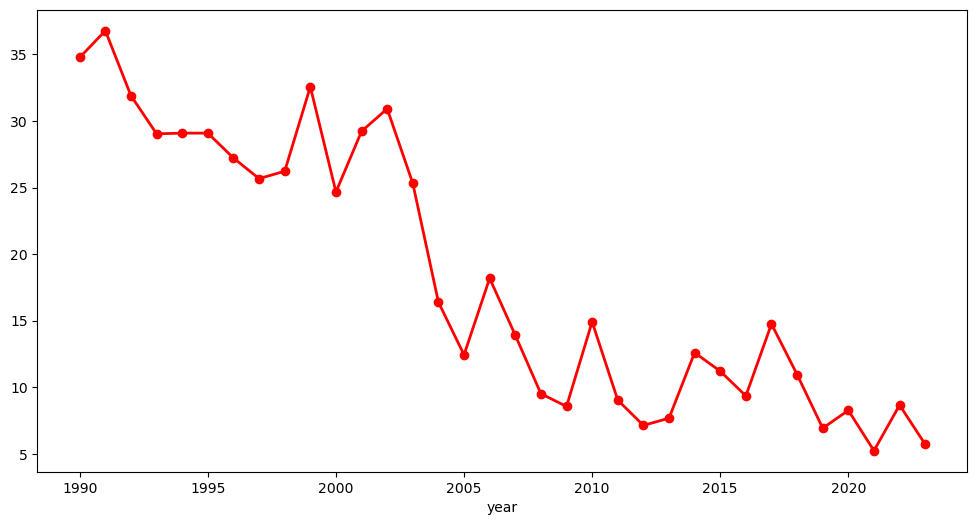

In [6]:
plt.figure(figsize=(12, 6))
tasa_mecanica.plot(
    marker='o',
    markersize=6,
    linewidth=2,
    color='red'
)
plt.show()

Media movil de fallos mecanicos 1990 - 2023

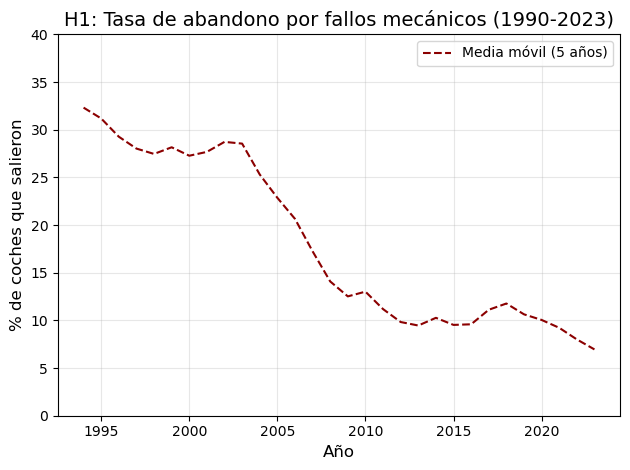

In [7]:
# Media móvil para ver tendencia
tasa_mecanica.rolling(window=5).mean().plot(
    color='darkred',
    linestyle='--',
    label='Media móvil (5 años)'
)

plt.title('H1: Tasa de abandono por fallos mecánicos (1990-2023)', fontsize=14)
plt.xlabel('Año', fontsize=12)
plt.ylabel('% de coches que salieron', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 40)  # Ajusta según tus datos
plt.tight_layout()
plt.show()

Me quedo con este gráfico para la presentacion

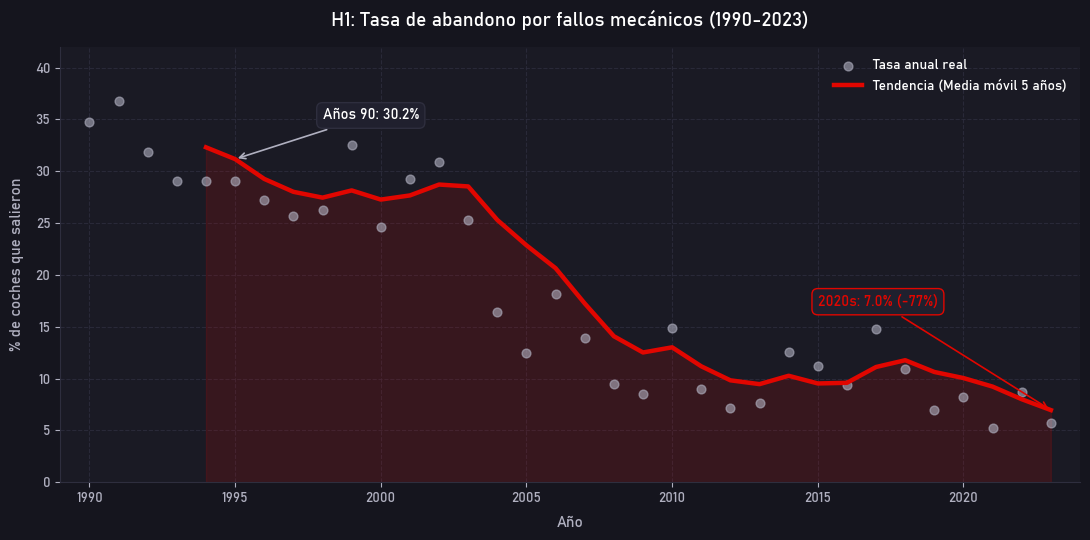

In [8]:
# ==============================================================================
# Gráfica definitiva H1: Estilo F1 Broadcast (Aislada con plt.rc_context)
# ==============================================================================
BG_COLOR    = '#15151E'   # Fondo negro carbón oficial F1
AX_COLOR    = '#1A1A24'   # Fondo interior de los ejes
BLANCO_F1   = '#FFFFFF'   # Texto principal
PLATA_F1    = '#B0B0C0'   # Textos secundarios y puntos anuales
GRID_COLOR  = '#2E2E3E'   # Rejilla oscura sutil

mm5 = tasa_mecanica.rolling(window=5).mean()

# El estilo F1 Dark + Bahnschrift SOLO se aplica dentro de este bloque
with plt.rc_context({
    'font.family': 'Bahnschrift',
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.titlepad': 15,
    'axes.labelsize': 11,
    'axes.labelweight': 'normal',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'grid.color': GRID_COLOR,
    'grid.linestyle': '--',
    'grid.alpha': 0.8,
    'legend.frameon': False,
    'legend.fontsize': 10,
    'figure.facecolor': BG_COLOR,
    'axes.facecolor': AX_COLOR
}):
    fig, ax = plt.subplots(figsize=(11, 5.5))

    # 1. Puntos anuales reales (plata sutil)
    ax.scatter(
        tasa_mecanica.index, 
        tasa_mecanica.values,
        color=PLATA_F1, 
        s=40, 
        alpha=0.6, 
        label='Tasa anual real',
        zorder=3
    )

    # 2. Línea protagonista roja F1 (telemetría)
    ax.plot(
        mm5.index, 
        mm5.values,
        color=ROJO_F1, 
        linestyle='-', 
        linewidth=3.2, 
        label='Tendencia (Media móvil 5 años)',
        zorder=4
    )

    # 3. Sombreado rojo bajo la curva
    ax.fill_between(
        mm5.index, 
        mm5.values, 
        color=ROJO_F1, 
        alpha=0.15, 
        zorder=2
    )

    # 4. Anotaciones telemetría con cajas oscuras integradas
    ax.annotate(
        'Años 90: 30.2%', 
        xy=(1995, mm5.loc[1995]), 
        xytext=(1998, 35),
        arrowprops=dict(arrowstyle='->', color=PLATA_F1, lw=1.2),
        fontsize=10.5, 
        fontweight='bold', 
        color=BLANCO_F1,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#20202E', edgecolor=GRID_COLOR)
    )

    ax.annotate(
        '2020s: 7.0% (-77%)', 
        xy=(2023, mm5.loc[2023]), 
        xytext=(2015, 17),
        arrowprops=dict(arrowstyle='->', color=ROJO_F1, lw=1.2),
        fontsize=10.5, 
        fontweight='bold', 
        color=ROJO_F1,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#20202E', edgecolor=ROJO_F1)
    )

    # 5. Títulos y etiquetas
    ax.set_title('H1: Tasa de abandono por fallos mecánicos (1990-2023)', color=BLANCO_F1)
    ax.set_xlabel('Año', color=PLATA_F1, labelpad=8)
    ax.set_ylabel('% de coches que salieron', color=PLATA_F1, labelpad=8)

    # 6. Ejes, ticks y grid
    ax.tick_params(colors=PLATA_F1)
    ax.set_ylim(0, 42)
    ax.set_xlim(1989, 2024)
    ax.grid(True)

    # Bordes (spines) limpios
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(GRID_COLOR)
    ax.spines['bottom'].set_color(GRID_COLOR)

    # Leyenda integrada con texto blanco
    legend = ax.legend(loc='upper right')
    for text in legend.get_texts():
        text.set_color(BLANCO_F1)

    plt.tight_layout()
    plt.show()

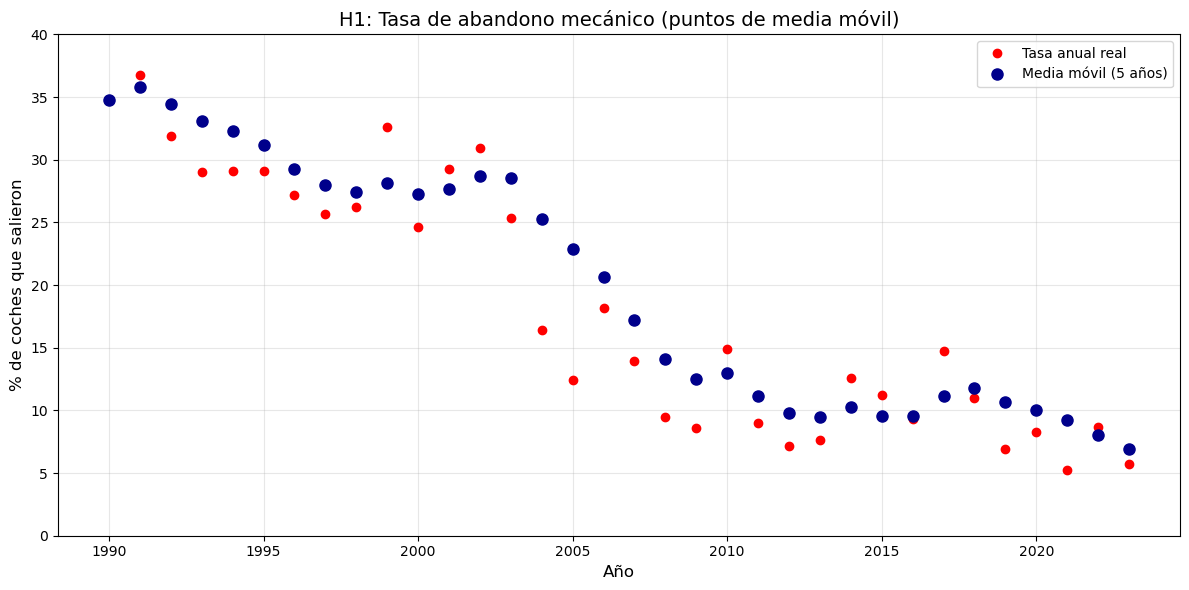

In [9]:
plt.figure(figsize=(12, 6))

# 1. Calcular la media móvil primero
media_movil = tasa_mecanica.rolling(window=5, min_periods=1).mean()

# 2. Graficar puntos de la tasa REAL
tasa_mecanica.plot(
    marker='o',
    markersize=6,
    linewidth=0,
    color='red',
    label='Tasa anual real'
)

# 3. Graficar puntos de la MEDIA MÓVIL
media_movil.plot(
    marker='o',
    markersize=8,
    linewidth=0,
    color='darkblue',
    label='Media móvil (5 años)'
)

# 4. Configuración
plt.title('H1: Tasa de abandono mecánico (puntos de media móvil)', fontsize=14)
plt.xlabel('Año', fontsize=12)
plt.ylabel('% de coches que salieron', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(0, 40)
plt.tight_layout()
plt.show()

In [10]:
# 1. Filtrar datos por décadas (3 opciones, elige una):

# OPCIÓN 1: Usando boolean indexing (recomendado)
tasa_90s = tasa_mecanica[(tasa_mecanica.index >= 1990) & (tasa_mecanica.index <= 1999)]
tasa_2020s = tasa_mecanica[(tasa_mecanica.index >= 2020) & (tasa_mecanica.index <= 2023)]

# OPCIÓN 2: Usando .loc (si el índice es numérico)
# tasa_90s = tasa_mecanica.loc[1990:1999]
# tasa_2020s = tasa_mecanica.loc[2020:2023]

# 2. Calcular medias
media_90s = tasa_90s.mean()
media_2020s = tasa_2020s.mean()

# 3. Calcular diferencias
diferencia_absoluta = media_90s - media_2020s
diferencia_porcentual = (diferencia_absoluta / media_90s) * 100

# 4. Mostrar resultados
print("=== DIFERENCIA DE TASA MECÁNICA ===")
print(f"Media años 90 (1990-1999): {media_90s:.1f}%")
print(f"Media años 2020 (2020-2023): {media_2020s:.1f}%")
print(f"Diferencia absoluta: {diferencia_absoluta:.1f} puntos porcentuales")
print(f"Diferencia relativa: {diferencia_porcentual:.1f}% de reducción")

=== DIFERENCIA DE TASA MECÁNICA ===
Media años 90 (1990-1999): 30.2%
Media años 2020 (2020-2023): 7.0%
Diferencia absoluta: 23.3 puntos porcentuales
Diferencia relativa: 77.0% de reducción


Con la media movil, podemos ver como la tasa de abandono por problemas mecanicos ha pasado de un 33% en 1994 a un 6% - 7% en 2023. Por lo tanto, se puede afirmar que la primera hipotesis es cierta ya que hemos pasado de una tasa media en los 90 de 30,2% a un 7% en los 2020s, con una diferencia absoluta de 23 puntos porcentuales y una diferencia relativa de un 77%, estando por debajo del objetivo establecido en la hipotesis (10%) para que sea cierta.